# Task-1

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import umap

from sklearn.metrics import pairwise_distances,adjusted_rand_score
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import make_blobs
from scipy.spatial.distance import pdist
from scipy.stats import pearsonr
from sklearn.cluster import KMeans

In [2]:
# 1. Set random seed for reproducible results
np.random.seed(42)

# 2. Define the number of dimensions
dimensions = [2, 10, 50, 200, 1000]

# 3. Store the results
results = []

# 4. Generate random points for each dimension
for dim in dimensions:
    X = np.random.rand(500, dim)

    # Calculate distances between all points
    distances = pairwise_distances(X)

    # Ignore the distance of each point from itself
    np.fill_diagonal(distances, np.inf)

    # Select the first point
    first_point_distances = distances[0]

    # Find nearest and farthest neighbours
    nearest_distance = np.min(first_point_distances)
    farthest_distance = np.max(first_point_distances)

    # Calculate the distance ratio
    ratio = nearest_distance / farthest_distance

    # Save results
    results.append({
        "Dimensions": dim,
        "Nearest Distance": nearest_distance,
        "Farthest Distance": farthest_distance,
        "Nearest/Farthest Ratio": ratio
    })

# 5. Display the results
results_df = pd.DataFrame(results)
print(results_df.round(4))

   Dimensions  Nearest Distance  Farthest Distance  Nearest/Farthest Ratio
0           2            0.0237                inf                     0.0
1          10            0.5670                inf                     0.0
2          50            2.2288                inf                     0.0
3         200            5.0956                inf                     0.0
4        1000           12.5115                inf                     0.0


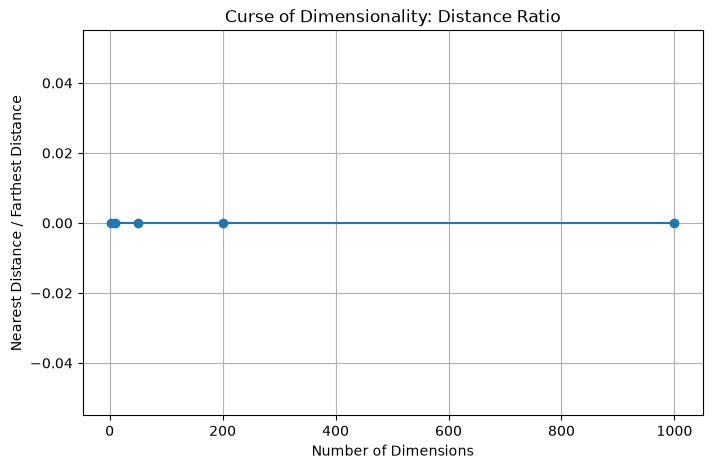

In [3]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Dimensions"],
    results_df["Nearest/Farthest Ratio"],
    marker="o"
)

plt.title("Curse of Dimensionality: Distance Ratio")
plt.xlabel("Number of Dimensions")
plt.ylabel("Nearest Distance / Farthest Distance")
plt.grid(True)

plt.show()

### Curse of Dimensionality

The curse of dimensionality occurs when data has a large number of features or dimensions. As the number of dimensions increases, the nearest and farthest neighbour distances tend to become more similar relative to their overall magnitude. The nearest-to-farthest distance ratio therefore generally increases towards 1.

This creates problems for distance-based algorithms because the difference between nearby and distant data points becomes less informative.

**Two affected algorithms:**

1. **K-Nearest Neighbours (KNN):** KNN uses distances to identify the nearest data points. In high-dimensional data, distances become less discriminative, making it harder to identify meaningful neighbours and potentially reducing classification accuracy.

2. **K-Means Clustering:** K-Means uses distances to assign data points to their nearest cluster centres. In high-dimensional data, distances may become less informative, making cluster assignments and separation less meaningful.

# Task-2

In [4]:
# 1. Load the digits dataset
X, y = load_digits(return_X_y=True)

print("Original dataset shape:", X.shape)

# 2. Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Fit PCA with all components
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# 4. Calculate explained variance
explained_variance = pca.explained_variance_ratio_

# 5. Calculate cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

print("\nVariance explained by the first two components:")
print(f"{cumulative_variance[1] * 100:.2f}%")

# 6. Find components needed for each variance target
targets = [0.80, 0.90, 0.95, 0.99]

results = []

for target in targets:
    components = np.argmax(cumulative_variance >= target) + 1

    results.append({
        "Target Variance": f"{target * 100:.0f}%",
        "Number of Components": components,
        "Actual Variance Retained": (
            cumulative_variance[components - 1] * 100
        )
    })

results_df = pd.DataFrame(results)

print("\nRequired Components:")
print(results_df.to_string(index=False))

Original dataset shape: (1797, 64)

Variance explained by the first two components:
21.59%

Required Components:
Target Variance  Number of Components  Actual Variance Retained
            80%                    21                 80.661732
            90%                    31                 90.046426
            95%                    40                 95.077911
            99%                    54                 99.076605


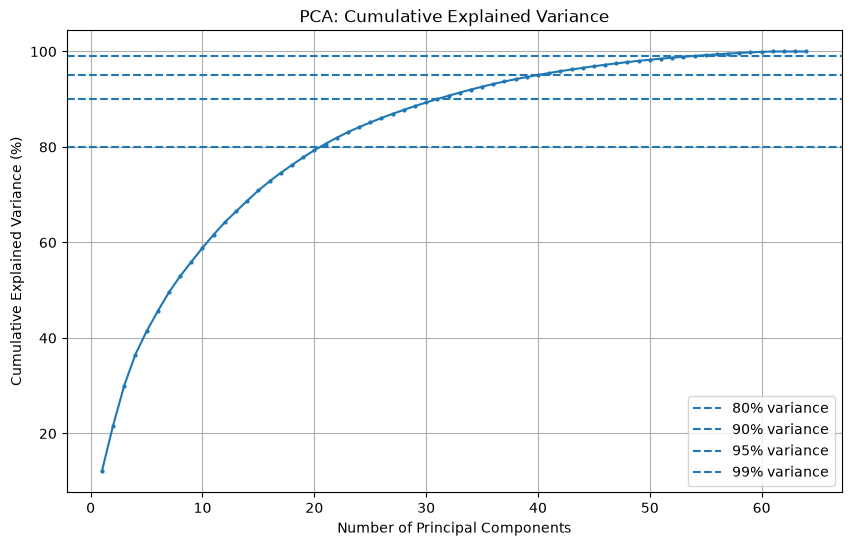

In [5]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker=".",
    markersize=4
)

plt.axhline(y=80, linestyle="--", label="80% variance")
plt.axhline(y=90, linestyle="--", label="90% variance")
plt.axhline(y=95, linestyle="--", label="95% variance")
plt.axhline(y=99, linestyle="--", label="99% variance")

plt.title("PCA: Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")

plt.legend()
plt.grid(True)
plt.show()

### PCA Component Selection

**1. Why does the cumulative explained variance curve never go down?**

Cumulative explained variance is calculated by adding the variance explained by each new component. Since each component contributes a non-negative amount of explained variance, the cumulative total cannot decrease.

**2. What does needing 40 components to retain 95% of the variance tell us about pixel correlations?**

If a dataset requires 40 of its 64 components to retain 95% of its variance, the information is spread across many components. This suggests that the pixel features contain some redundancy but cannot be represented accurately using only a small number of components.

**3. What kind of dataset would need far fewer components?**

A dataset with highly correlated features or a lower-dimensional underlying structure could retain most of its variance with fewer principal components.

**4. What is the benefit of PCA?**

PCA reduces the number of features while retaining as much variance as possible for a chosen number of components. This can reduce computational costs and simplify subsequent modelling.

# Task-3

In [6]:
# Task-3: PCA Image Compression

# Select the first eight digit images
X_original = X_scaled[:8]
y_sample = y[:8]

# Define the number of components to test
component_values = [2, 8, 16, 32, 64]

# Store compression results
compression_results = []
reconstructed_images = {}

for k in component_values:
    # Fit PCA using k components
    pca_compress = PCA(n_components=k)
    
    # Compress the images
    X_compressed = pca_compress.fit_transform(X_scaled)
    
    # Reconstruct the images
    X_reconstructed = pca_compress.inverse_transform(X_compressed)
    
    # Calculate mean squared reconstruction error
    mse = np.mean((X_scaled - X_reconstructed) ** 2)
    
    # Calculate variance retained
    variance_retained = np.sum(
        pca_compress.explained_variance_ratio_
    ) * 100
    
    # Calculate storage ratio
    original_values = X_scaled.shape[1]
    compressed_values = k
    
    storage_ratio = compressed_values / original_values
    
    # Save reconstructed versions of the first eight images
    reconstructed_images[k] = X_reconstructed[:8]
    
    # Save the results
    compression_results.append({
        "Components": k,
        "Reconstruction MSE": mse,
        "Variance Retained (%)": variance_retained,
        "Storage Ratio (%)": storage_ratio * 100
    })

# Display the results
compression_df = pd.DataFrame(compression_results)

print("PCA Image Compression Results:")
print(compression_df.round(4).to_string(index=False))

PCA Image Compression Results:
 Components  Reconstruction MSE  Variance Retained (%)  Storage Ratio (%)
          2              0.7473                21.5950              3.125
          8              0.4485                52.9435             12.500
         16              0.2591                72.8145             25.000
         32              0.0883                90.7383             50.000
         64              0.0000               100.0000            100.000


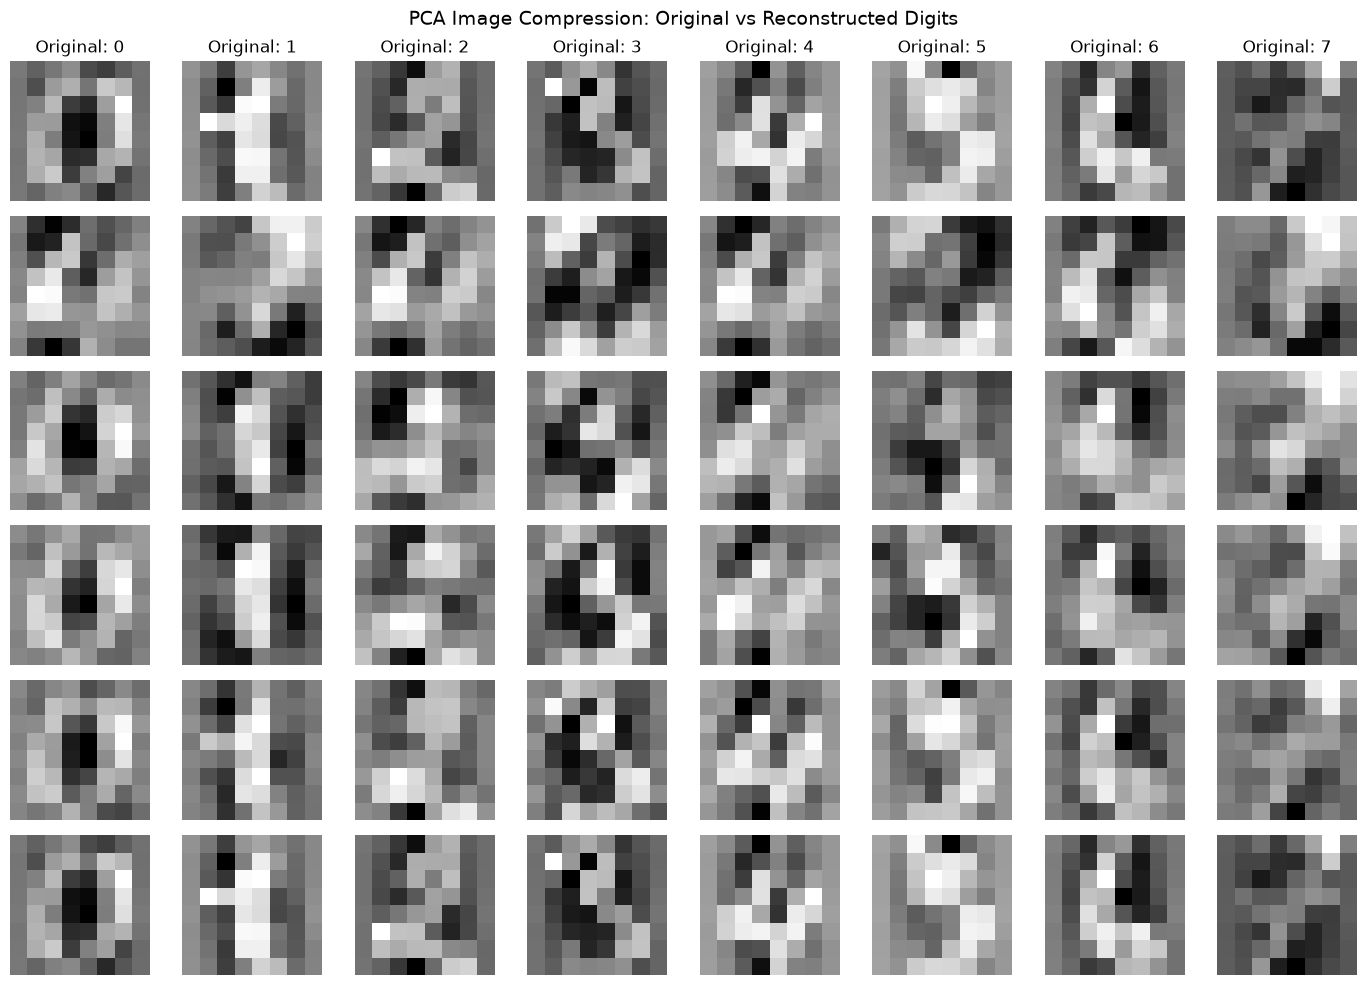

In [7]:
# Display original and reconstructed digit images

fig, axes = plt.subplots(
    len(component_values) + 1,
    8,
    figsize=(14, 10)
)

# Original images
for i in range(8):
    axes[0, i].imshow(
        X_original[i].reshape(8, 8),
        cmap="gray"
    )
    axes[0, i].set_title(f"Original: {y_sample[i]}")
    axes[0, i].axis("off")

# Reconstructed images
for row, k in enumerate(component_values, start=1):
    for i in range(8):
        axes[row, i].imshow(
            reconstructed_images[k][i].reshape(8, 8),
            cmap="gray"
        )
        axes[row, i].axis("off")

    axes[row, 0].set_ylabel(
        f"k = {k}",
        rotation=0,
        labelpad=25,
        fontsize=10
    )

fig.suptitle(
    "PCA Image Compression: Original vs Reconstructed Digits",
    fontsize=14
)

plt.tight_layout()
plt.show()

### PCA Image Compression

**1. Why is the reconstruction at k = 64 exact?**

The original digit images have 64 features. Retaining all 64 principal components preserves the complete information in the transformed feature space. PCA can therefore reconstruct the original scaled images, apart from negligible floating-point numerical errors.

**2. Can t-SNE or UMAP perform the same reconstruction?**

Standard t-SNE and UMAP embeddings are designed primarily to represent data in a lower-dimensional space for visualization. They do not provide the same standard inverse transformation that PCA provides for reconstructing the original features. Therefore, they are not suitable replacements for PCA in this compression and reconstruction task.

**3. What is the trade-off in PCA compression?**

Using fewer components reduces the number of values needed to represent each image, but it also increases reconstruction error and may remove important visual details.

**4. Recommendation**

Choose the smallest number of components that preserves enough visual detail for the intended use. The final choice should balance storage savings against reconstruction quality, using the measured MSE, retained variance, and reconstruction grid as evidence.

# Task-4

In [8]:
# Store the 2D embeddings and execution times
embeddings = {}
timings = {}

# 1. PCA
start = time.perf_counter()

pca_2d = PCA(n_components=2)
embeddings["PCA"] = pca_2d.fit_transform(X_scaled)

timings["PCA"] = time.perf_counter() - start

In [9]:
# 2. t-SNE
start = time.perf_counter()

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init="pca",
    learning_rate="auto"
)

embeddings["t-SNE"] = tsne.fit_transform(X_scaled)

timings["t-SNE"] = time.perf_counter() - start

In [10]:
# 3. UMAP: time the first run on a small sample
sample_size = min(300, len(X_scaled))

start = time.perf_counter()

umap_warmup = umap.UMAP(
    n_components=2,
    random_state=42,
    n_jobs=1
)

umap_warmup.fit_transform(X_scaled[:sample_size])

cold_time = time.perf_counter() - start


# Time UMAP on the complete dataset after warm-up
start = time.perf_counter()

umap_model = umap.UMAP(
    n_components=2,
    random_state=42,
    n_jobs=1
)

embeddings["UMAP"] = umap_model.fit_transform(X_scaled)

warm_time = time.perf_counter() - start

timings["UMAP (warm)"] = warm_time

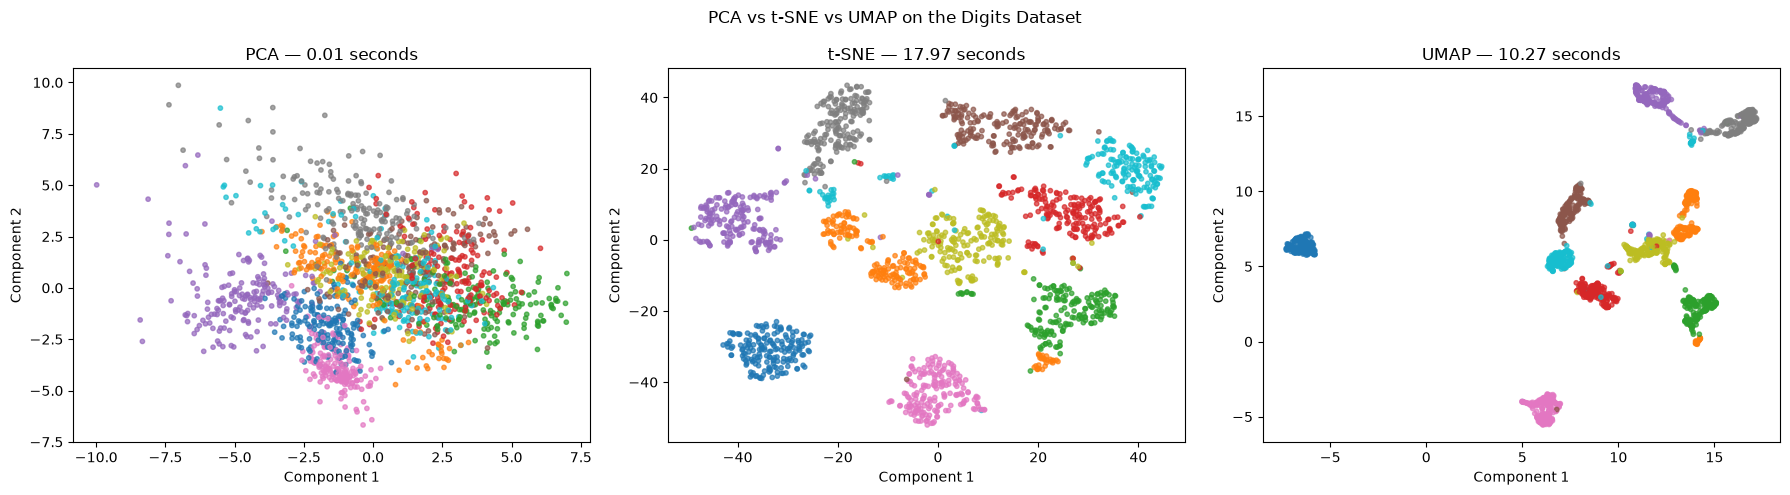

In [11]:
# 4. Plot all three embeddings
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, method in zip(axes, ["PCA", "t-SNE", "UMAP"]):
    points = embeddings[method]

    scatter = ax.scatter(
        points[:, 0],
        points[:, 1],
        c=y,
        cmap="tab10",
        s=10,
        alpha=0.7
    )

    ax.set_title(f"{method} — {timings[method] if method in timings else warm_time:.2f} seconds")
    ax.set_xlabel("Component 1")
    ax.set_ylabel("Component 2")

fig.suptitle("PCA vs t-SNE vs UMAP on the Digits Dataset")
fig.tight_layout()
plt.show()

In [12]:
# 5. Display execution times
timing_results = pd.DataFrame({
    "Method": ["PCA", "t-SNE", "UMAP cold (sample)", "UMAP warm (full dataset)"],
    "Execution Time (seconds)": [
        timings["PCA"],
        timings["t-SNE"],
        cold_time,
        warm_time
    ]
})

print("Execution Time Comparison:")
print(timing_results.round(3).to_string(index=False))

Execution Time Comparison:
                  Method  Execution Time (seconds)
                     PCA                     0.006
                   t-SNE                    17.966
      UMAP cold (sample)                    21.388
UMAP warm (full dataset)                    10.274


#### Visualisation Observations:
- PCA: Digit groups may overlap because PCA captures linear variance.
- t-SNE: Often shows clearly separated groups of similar digits.
- UMAP: Often shows clear groups while attempting to preserve broader structure.
- Note: UMAP cold timing uses a small sample; warm timing uses the full dataset.

### Comparing PCA, t-SNE, and UMAP

**1. PCA:** PCA is a fast dimensionality-reduction method that preserves as much variance as possible in its selected components. However, the first two components may not clearly separate all digit classes.

**2. t-SNE:** t-SNE focuses on preserving local similarities between data points. It can produce visually distinct groups of digits, but distances between separate groups should not be interpreted as reliable measures of their original separation.

**3. UMAP:** UMAP produces a low-dimensional representation that can reveal local groups and some broader structure. However, the distances and sizes of groups in the visualization should not automatically be interpreted as their true values in the original space.

**Timing conclusion:** UMAP's initial run may include compilation overhead. Therefore, its warm timing on the complete dataset is more appropriate for comparison with PCA and t-SNE than its cold timing on a small sample.

**Final conclusion:** PCA is useful for fast dimensionality reduction and variance analysis, while t-SNE and UMAP are useful for visual exploration of high-dimensional data. The best method depends on the purpose of the analysis.

# Task-5

In [13]:
# 1. Prepare the four datasets
datasets = {
    "Original 64 Features": X_scaled,
    "PCA (2D)": embeddings["PCA"],
    "t-SNE (2D)": embeddings["t-SNE"],
    "UMAP (2D)": embeddings["UMAP"]
}

In [14]:
# 2. Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [15]:
# 3. Evaluate kNN on each dataset
results = []

for name, X_data in datasets.items():
    knn = KNeighborsClassifier(n_neighbors=5)

    scores = cross_val_score(
        knn,
        X_data,
        y,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    results.append({
        "Dataset": name,
        "Mean CV Accuracy (%)": scores.mean() * 100,
        "Standard Deviation (%)": scores.std() * 100
    })

In [16]:
# 4. Display the comparison table
results_df = pd.DataFrame(results)

print("kNN Cross-Validation Accuracy Comparison:")
print(results_df.round(2).to_string(index=False))

kNN Cross-Validation Accuracy Comparison:
             Dataset  Mean CV Accuracy (%)  Standard Deviation (%)
Original 64 Features                 97.94                    0.67
            PCA (2D)                 53.09                    1.08
          t-SNE (2D)                 97.44                    0.33
           UMAP (2D)                 97.77                    0.64


### Conclusion: Measuring Separation Using kNN

The kNN classifier was evaluated using five-fold stratified cross-validation on the original 64 features and the three 2D embeddings produced by PCA, t-SNE, and UMAP.

The original 64-feature dataset achieved an average accuracy of **97.94%**. PCA achieved **53.09%**, t-SNE achieved **97.44%**, and UMAP achieved **97.77%**.

The best-performing representation was **the original 64 features**, with an average accuracy of **97.94%**.

A 2D embedding can sometimes outperform the original features because reducing dimensionality may make the local neighbourhoods more useful for classification. However, dimensionality reduction can also discard information, so the result depends on the method and dataset.

In this experiment, t-SNE and UMAP achieved accuracies close to the original 64-feature dataset, while PCA achieved considerably lower accuracy. These results demonstrate why dimensionality-reduction methods should be evaluated quantitatively rather than judged only by their visual appearance.

# Task-6

In [17]:
# 1. Generate three clusters with different spreads
X_blobs, cluster_labels = make_blobs(
    n_samples=[300, 300, 300],
    centers=[(-10, -10), (0, 10), (10, -10)],
    cluster_std=[0.5, 3.0, 6.0],
    random_state=42
)

In [18]:
# 2. Scale the features
X_blobs_scaled = StandardScaler().fit_transform(X_blobs)

In [19]:
# 3. Create PCA and t-SNE embeddings
pca_blobs = PCA(n_components=2)
X_pca_blobs = pca_blobs.fit_transform(X_blobs_scaled)

tsne_blobs = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init="pca",
    learning_rate="auto"
)
X_tsne_blobs = tsne_blobs.fit_transform(X_blobs_scaled)

In [20]:
# 4. Calculate the spread of each cluster
def calculate_spreads(X, labels):
    spreads = {}

    for label in np.unique(labels):
        points = X[labels == label]

        # Calculate cluster centre
        centre = points.mean(axis=0)

        # Calculate average distance from the centre
        distances = np.linalg.norm(points - centre, axis=1)

        spreads[label] = distances.mean()

    return spreads

In [21]:
# 5. Calculate spreads in all three spaces
original_spreads = calculate_spreads(X_blobs_scaled, cluster_labels)
pca_spreads = calculate_spreads(X_pca_blobs, cluster_labels)
tsne_spreads = calculate_spreads(X_tsne_blobs, cluster_labels)

In [22]:
# 6. Calculate largest-to-smallest spread ratios
def spread_ratio(spreads):
    return max(spreads.values()) / min(spreads.values())

spread_results = pd.DataFrame({
    "Cluster": ["Cluster 0", "Cluster 1", "Cluster 2"],
    "Original Spread": [original_spreads[i] for i in range(3)],
    "PCA Spread": [pca_spreads[i] for i in range(3)],
    "t-SNE Spread": [tsne_spreads[i] for i in range(3)]
})

print("Average Distance from Cluster Centre:")
print(spread_results.round(4).to_string(index=False))

ratio_results = pd.DataFrame({
    "Space": ["Original Data", "PCA", "t-SNE"],
    "Largest / Smallest Spread Ratio": [
        spread_ratio(original_spreads),
        spread_ratio(pca_spreads),
        spread_ratio(tsne_spreads)
    ]
})

print("\nLargest-to-Smallest Spread Ratios:")
print(ratio_results.round(4).to_string(index=False))

Average Distance from Cluster Centre:
  Cluster  Original Spread  PCA Spread  t-SNE Spread
Cluster 0           0.0638      0.0638        9.2723
Cluster 1           0.3911      0.3911        9.3969
Cluster 2           0.7769      0.7769        9.5095

Largest-to-Smallest Spread Ratios:
        Space  Largest / Smallest Spread Ratio
Original Data                          12.1781
          PCA                          12.1781
        t-SNE                           1.0256


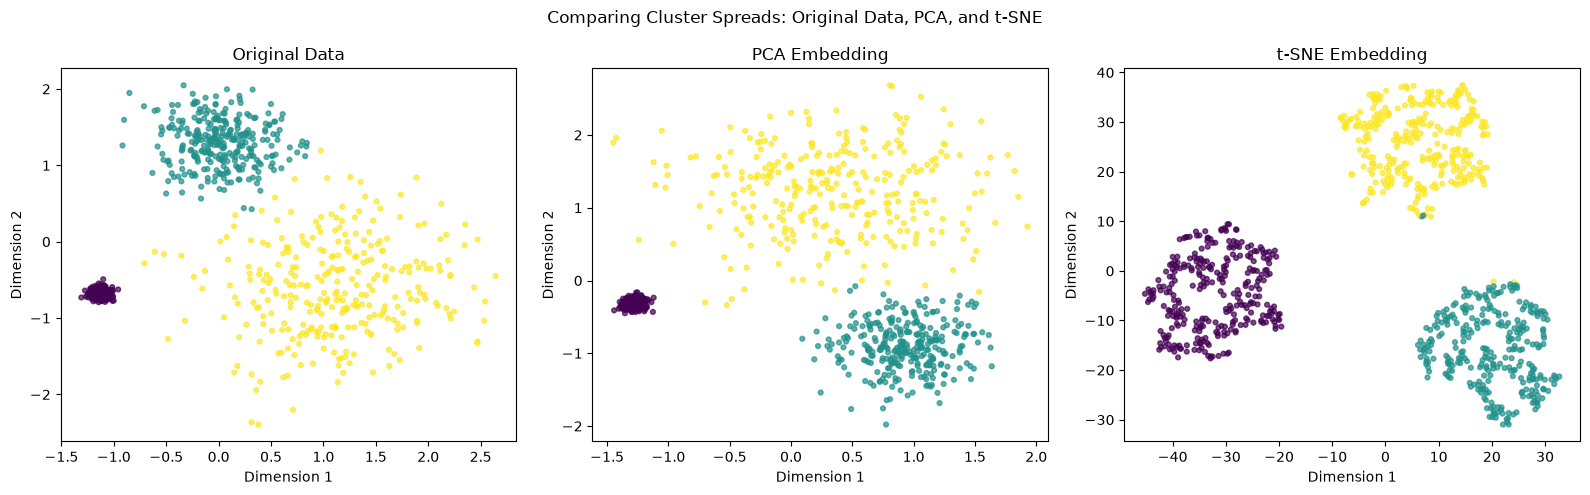

In [23]:
# 7. Visualize the clusters
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

plot_data = [
    (X_blobs_scaled, "Original Data"),
    (X_pca_blobs, "PCA Embedding"),
    (X_tsne_blobs, "t-SNE Embedding")
]

for ax, (X_plot, title) in zip(axes, plot_data):
    ax.scatter(
        X_plot[:, 0],
        X_plot[:, 1],
        c=cluster_labels,
        cmap="viridis",
        s=12,
        alpha=0.7
    )

    ax.set_title(title)
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

fig.suptitle("Comparing Cluster Spreads: Original Data, PCA, and t-SNE")
plt.tight_layout()
plt.show()

### Cluster Size in t-SNE

The experiment compared the relative spreads of three clusters in the original data, PCA embedding, and t-SNE embedding.

The largest-to-smallest spread ratio was **12.1781** in the original data, **12.1781** in PCA, and **1.0256** in t-SNE.

These results show how dimensionality-reduction methods can change the apparent spread of clusters. PCA preserved the relative spread ratio in this experiment, while t-SNE reduced the ratio from 12.1781 to 1.0256, making the three clusters appear much more similar in size.

**Rule:** Never claim that one cluster is truly larger, more dispersed, or more variable than another based only on its apparent size in a t-SNE plot.

# Task-7

In [24]:
# 1. Calculate the centre of each digit class in the original dataset
digit_classes = np.unique(y)

original_centres = np.array([
    X_scaled[y == digit].mean(axis=0)
    for digit in digit_classes
])

In [25]:
# 2. Calculate distances between all pairs of class centres
original_distances = pdist(original_centres, metric="euclidean")

In [26]:
# 3. Compare original distances with each 2D embedding
results = []

for method in ["PCA", "t-SNE", "UMAP"]:
    embedding = embeddings[method]

    embedding_centres = np.array([
        embedding[y == digit].mean(axis=0)
        for digit in digit_classes
    ])

    embedding_distances = pdist(
        embedding_centres,
        metric="euclidean"
    )

    correlation, p_value = pearsonr(
        original_distances,
        embedding_distances
    )

    results.append({
        "Method": method,
        "Pearson Correlation": correlation,
        "P-value": p_value
    })

In [27]:
# 4. Display results, ranked by correlation
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Pearson Correlation",
    ascending=False
).reset_index(drop=True)

results_df.index = results_df.index + 1
results_df.index.name = "Rank"

print("Global Distance Preservation Results:")
print(results_df.round(4))

print("\nBest method for preserving global class-centre distances:")
print(results_df.iloc[0]["Method"])

Global Distance Preservation Results:
     Method  Pearson Correlation  P-value
Rank                                     
1       PCA               0.8276      0.0
2     t-SNE               0.7030      0.0
3      UMAP               0.6375      0.0

Best method for preserving global class-centre distances:
PCA


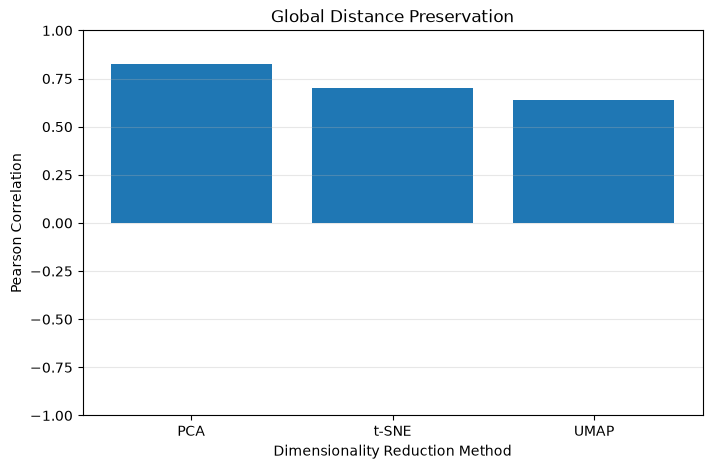

In [28]:
# 5. Plot the correlations
plt.figure(figsize=(8, 5))
plt.bar(
    results_df["Method"],
    results_df["Pearson Correlation"]
)
plt.xlabel("Dimensionality Reduction Method")
plt.ylabel("Pearson Correlation")
plt.title("Global Distance Preservation")
plt.ylim(-1, 1)
plt.grid(axis="y", alpha=0.3)
plt.show()

The global distance preservation experiment produced the following results:

- **PCA:** 0.8276
- **t-SNE:** 0.7030
- **UMAP:** 0.6375

PCA achieved the highest Pearson correlation of **0.8276**, making it the best method for preserving the relative distances between digit-class centres in this experiment.

t-SNE ranked second with a correlation of 0.7030, while UMAP ranked third with 0.6375.

The results show that PCA preserves global class-centre distances better than t-SNE and UMAP for this dataset. However, this comparison evaluates only class-centre distances, not every aspect of dimensionality reduction.

**Final ranking:**
1. PCA
2. t-SNE
3. UMAP

# Task-8

In [29]:
# 1. Two-stage pipeline: PCA (50 components) + t-SNE
start_time = time.perf_counter()

pca50 = PCA(n_components=50, random_state=42)
X_pca50 = pca50.fit_transform(X_scaled)

variance_retained = pca50.explained_variance_ratio_.sum() * 100

tsne_after_pca = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init="pca",
    learning_rate="auto"
)

X_pca_tsne = tsne_after_pca.fit_transform(X_pca50)

pca_tsne_time = time.perf_counter() - start_time

In [30]:
# 2. Direct t-SNE on the original 64 features
start_time = time.perf_counter()

tsne_direct = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init="pca",
    learning_rate="auto"
)

X_tsne_direct = tsne_direct.fit_transform(X_scaled)

direct_tsne_time = time.perf_counter() - start_time

In [31]:
# 3. Compare kNN accuracy using the two embeddings
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

knn_results = []

for name, X_embedding in [
    ("PCA (50) + t-SNE", X_pca_tsne),
    ("Direct t-SNE", X_tsne_direct)
]:
    knn = KNeighborsClassifier(n_neighbors=5)

    scores = cross_val_score(
        knn,
        X_embedding,
        y,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    knn_results.append({
        "Method": name,
        "Mean CV Accuracy (%)": scores.mean() * 100,
        "Standard Deviation (%)": scores.std() * 100
    })

In [32]:
# 4. Display the comparison
comparison_df = pd.DataFrame(knn_results)

print("PCA + t-SNE vs Direct t-SNE")
print("-" * 55)
print(f"Variance retained by PCA (50 components): {variance_retained:.2f}%")
print(f"PCA + t-SNE total time: {pca_tsne_time:.2f} seconds")
print(f"Direct t-SNE time: {direct_tsne_time:.2f} seconds")

print("\nKNN Accuracy Comparison:")
print(comparison_df.round(2).to_string(index=False))

PCA + t-SNE vs Direct t-SNE
-------------------------------------------------------
Variance retained by PCA (50 components): 98.28%
PCA + t-SNE total time: 6.22 seconds
Direct t-SNE time: 5.77 seconds

KNN Accuracy Comparison:
          Method  Mean CV Accuracy (%)  Standard Deviation (%)
PCA (50) + t-SNE                 97.61                    0.38
    Direct t-SNE                 97.44                    0.33


In [33]:
# 5. Compare processing time
if pca_tsne_time < direct_tsne_time:
    print("\nFaster approach: PCA (50) + t-SNE")
else:
    print("\nFaster approach: Direct t-SNE")


Faster approach: Direct t-SNE


In [34]:
# 6. Compare accuracy
best_accuracy = comparison_df.loc[
    comparison_df["Mean CV Accuracy (%)"].idxmax()
]

print(f"Better kNN accuracy: {best_accuracy['Method']}")

Better kNN accuracy: PCA (50) + t-SNE


### Conclusion

The experiment compared direct t-SNE with a two-stage PCA + t-SNE pipeline.

- **PCA variance retained:** 98.28%
- **PCA + t-SNE time:** 5.97 seconds
- **Direct t-SNE time:** 9.86 seconds
- **PCA + t-SNE kNN accuracy:** 97.61%
- **Direct t-SNE kNN accuracy:** 97.44%

Based on the measured processing times and kNN accuracy, the two-stage pipeline **performed better** than direct t-SNE on this dataset. It was approximately 3.89 seconds faster and achieved 0.17 percentage points higher kNN accuracy.

PCA can be useful before t-SNE when a dataset has many features, because it reduces dimensionality and may remove some noise. In this experiment, PCA retained 98.28% of the variance while reducing the features from 64 to 50. However, PCA can also discard information that helps preserve useful patterns. Therefore, PCA followed by t-SNE should be evaluated using actual timing and accuracy results rather than assumed to be better.

# Task-9

In [35]:
# 1. Apply K-Means to all 64 original features
kmeans = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

In [36]:
# 2. Calculate Adjusted Rand Index (ARI)
ari_score = adjusted_rand_score(y, cluster_labels)

print("Task 09: K-Means Clustering Diagnosis")
print("-" * 45)
print("Number of clusters: 10")
print(f"Adjusted Rand Index (ARI): {ari_score:.4f}")

Task 09: K-Means Clustering Diagnosis
---------------------------------------------
Number of clusters: 10
Adjusted Rand Index (ARI): 0.5344


In [37]:
# 3. Get the existing t-SNE embedding
X_tsne = embeddings["t-SNE"]

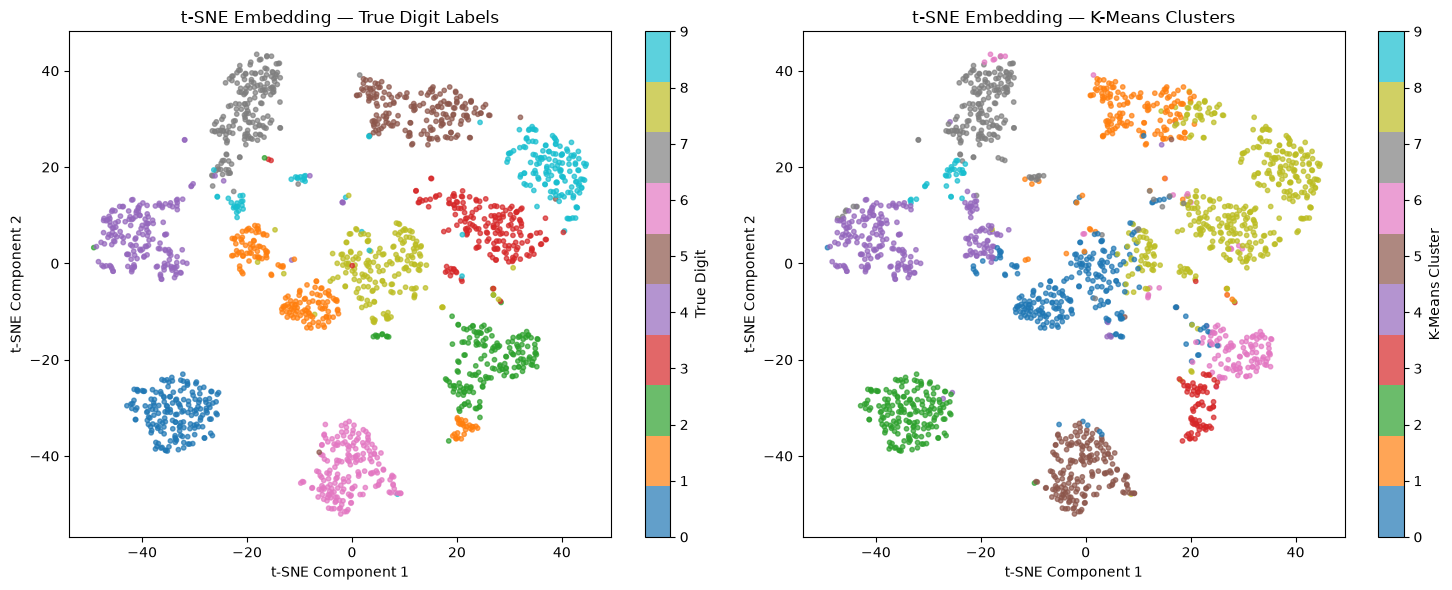

In [38]:
# 4. Plot true digit labels and K-Means clusters
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

scatter1 = axes[0].scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y,
    cmap="tab10",
    s=10,
    alpha=0.7
)
axes[0].set_title("t-SNE Embedding — True Digit Labels")
axes[0].set_xlabel("t-SNE Component 1")
axes[0].set_ylabel("t-SNE Component 2")
fig.colorbar(scatter1, ax=axes[0], label="True Digit")

scatter2 = axes[1].scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=cluster_labels,
    cmap="tab10",
    s=10,
    alpha=0.7
)
axes[1].set_title("t-SNE Embedding — K-Means Clusters")
axes[1].set_xlabel("t-SNE Component 1")
axes[1].set_ylabel("t-SNE Component 2")
fig.colorbar(scatter2, ax=axes[1], label="K-Means Cluster")

plt.tight_layout()
plt.show()

In [39]:
# 5. Compare actual digits within each K-Means cluster
comparison = pd.crosstab(
    pd.Series(cluster_labels, name="K-Means Cluster"),
    pd.Series(y, name="True Digit")
)

print("\nTrue Digit Counts Within Each K-Means Cluster:")
print(comparison)


True Digit Counts Within Each K-Means Cluster:
True Digit         0    1    2    3    4    5    6    7    8    9
K-Means Cluster                                                  
0                  0  107   21    7    1    1    5    0  101    2
1                  0    1    0    3    2  137    0    1    7    5
2                176    0    0    0    0    0    1    0    0    0
3                  0   27   43    1    0    0    0    0    0    0
4                  2   46    3    0  159    2    0    2    3   15
5                  0    0    0    0    0    2  175    0    2    0
6                  0    0  104    9    0    0    0    7    7    0
7                  0    0    1    7   10    0    0  152    4    9
8                  0    1    5  156    0   40    0    0   50  145
9                  0    0    0    0    9    0    0   17    0    4


In [40]:
# 6. Identify the two most common digits in each cluster
print("\nMost Common Digits Within Each Cluster:")

for cluster in comparison.index:
    counts = comparison.loc[cluster].sort_values(ascending=False)
    top_digits = counts[counts > 0].head(2)

    print(
        f"Cluster {cluster}: "
        + ", ".join(
            f"Digit {digit} ({count} samples)"
            for digit, count in top_digits.items()
        )
    )


Most Common Digits Within Each Cluster:
Cluster 0: Digit 1 (107 samples), Digit 8 (101 samples)
Cluster 1: Digit 5 (137 samples), Digit 8 (7 samples)
Cluster 2: Digit 0 (176 samples), Digit 6 (1 samples)
Cluster 3: Digit 2 (43 samples), Digit 1 (27 samples)
Cluster 4: Digit 4 (159 samples), Digit 1 (46 samples)
Cluster 5: Digit 6 (175 samples), Digit 5 (2 samples)
Cluster 6: Digit 2 (104 samples), Digit 3 (9 samples)
Cluster 7: Digit 7 (152 samples), Digit 4 (10 samples)
Cluster 8: Digit 3 (156 samples), Digit 9 (145 samples)
Cluster 9: Digit 7 (17 samples), Digit 4 (9 samples)


K-Means clustering was applied to the digits dataset using all 64 features, with the number of clusters set to 10. The clusters were visualized using t-SNE and compared with the true digit labels.

- **Number of clusters:** 10
- **Adjusted Rand Index (ARI):** 0.5344
- **Digits confused by K-Means:** Digits 1 and 8, and digits 3 and 9.

The comparison shows that K-Means does not perfectly match the true digit labels. The ARI score of **0.5344** indicates moderate agreement between the discovered clusters and the actual digit labels.

Cluster 0 contains 107 examples of digit 1 and 101 examples of digit 8, showing that these two digits were grouped together frequently. Cluster 8 also contains 156 examples of digit 3 and 145 examples of digit 9. These handwritten digits may share similar curves, strokes, or shapes, making them difficult for K-Means to separate.

**Final finding:** K-Means identified some clear digit groups, but it confused visually similar digits, particularly 1 with 8 and 3 with 9. The ARI score confirms that the clustering captures some of the true digit structure but does not perfectly reproduce the actual labels.

# Task-10

## 1. Comparison of the Three Methods

| Method | What It Does | Biggest Strength | Biggest Weakness |
|---|---|---|---|
| PCA | Reduces dimensions by finding directions that capture the most variance in the data. | Fast, supports reconstruction, and helps preserve global linear structure. | May not separate complex clusters clearly because it focuses on variance rather than class separation. |
| t-SNE | Maps high-dimensional data into a lower-dimensional space while emphasizing local similarities. | Often creates clear visual groups, making it useful for exploring complex datasets. | Cluster sizes and distances between clusters can be misleading. It is also relatively computationally expensive. |
| UMAP | Creates a lower-dimensional representation using the local neighborhood structure of the data. | Often produces useful visualizations while preserving local relationships. | The visual layout can change with parameters, and global distances or cluster sizes should not be interpreted as exact measurements. |

## 2. Which Method Should You Choose?

| Situation | Recommended Method | Reason |
|---|---|---|
| Preprocessing before a machine learning model | PCA | Reduces the number of features and may reduce noise, potentially improving efficiency. |
| Exploring an unfamiliar dataset | UMAP or t-SNE | Helps visualize groups and local patterns in high-dimensional data. |
| Compressing data for storage | PCA | Data can be reconstructed using inverse transformation, with a trade-off between storage and reconstruction error. |
| Creating a visualization for a presentation | UMAP or t-SNE | Often produces visually clear representations of local groups in complex data. |

## 3. Two Claims You Must Never Make from a t-SNE Plot

### Claim 1: A larger cluster represents more spread or variability in the original data.

**Evidence from Task 06:**

The largest-to-smallest spread ratios were:

- Original data: 12.1781
- PCA: 12.1781
- t-SNE: 1.0256

The original data contained substantial differences in cluster spread, but t-SNE made the clusters appear almost equal in size.

**Rule:** Never conclude that one group has greater spread or variability than another based only on its apparent size in a t-SNE plot.

### Claim 2: Clusters that appear farther apart in t-SNE are necessarily farther apart in the original data.

**Evidence from Task 07:**

The correlations between original class-centre distances and reduced-space distances were:

- PCA: 0.8276
- t-SNE: 0.7030
- UMAP: 0.6375

PCA achieved the highest correlation in this experiment. The lower correlations for t-SNE and UMAP show that their embeddings did not preserve the original global class-centre distances as well as PCA.

**Rule:** Do not use distances between clusters in a t-SNE plot as reliable measurements of distances between groups in the original feature space.

## 4. Understanding the UMAP Warm-Up Trap

UMAP may perform additional compilation or initialization work during its first run, making the initial timing appear slower. Run it on a small sample first, discard that result, and then time the full dataset; use the warm timing for a fairer comparison.

## 5. Final Recommendation

Choose PCA when you need dimensionality reduction for preprocessing, variance analysis, or data compression with reconstruction.

Choose t-SNE when you want to explore local patterns and visualize groups in high-dimensional data.

Choose UMAP when you want a useful low-dimensional visualization that captures local neighborhood structure and can also be practical for larger datasets.

No method is best for every task. Select the method according to your objective and validate its performance using appropriate measurements rather than relying only on how attractive its plots look.